In [18]:
# ============================================================
# TRAVELTIDE – SESSIONS INSPECTION
# ============================================================

# 1. Import libraries
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from pathlib import Path
import shutil
from IPython.display import display

# Visualization settings
sns.set_theme(style="whitegrid")
plt.rcParams["figure.figsize"] = (12, 6)

# 2. Define project directories
PROJECT_DIR = Path(r"D:\MSIT_Schulungsunterlagen\Projekte\TravelTide")

SOURCE_FILE = PROJECT_DIR / "data" / "working" / "01_exploration" / "expl_sessions.csv"
CLEANING_DIR = PROJECT_DIR / "data" / "working" / "02_inspection"

TARGET_FILE = CLEANING_DIR / "insp_sessions.csv"

# 3. Create cleaning directory
CLEANING_DIR.mkdir(parents=True, exist_ok=True)

# 4. Check source file
if not SOURCE_FILE.is_file():
    raise FileNotFoundError(f"Source file not found: {SOURCE_FILE}")

# 5. Create cleaning copy
shutil.copy2(SOURCE_FILE, TARGET_FILE)

# 6. Load cleaning copy into DataFrame
sessions = pd.read_csv(TARGET_FILE)

# 7. Display loading report
print("=" * 60)
print("TRAVELTIDE – SESSIONS INSPECTION")
print("=" * 60)

print(f"Source:  {SOURCE_FILE}")
print(f"Target:  {TARGET_FILE}")
print(f"Rows:    {sessions.shape[0]:,}")
print(f"Columns: {sessions.shape[1]}")
print("Status:  SUCCESS")
print("=" * 60)


TRAVELTIDE – SESSIONS INSPECTION
Source:  D:\MSIT_Schulungsunterlagen\Projekte\TravelTide\data\working\01_exploration\expl_sessions.csv
Target:  D:\MSIT_Schulungsunterlagen\Projekte\TravelTide\data\working\02_inspection\insp_sessions.csv
Rows:    5,408,063
Columns: 13
Status:  SUCCESS


In [19]:
# Allgemeine Informationen zum Datensatz
sessions.info()

# Statistische Zusammenfassung aller Spalten
display(sessions.describe(include="all").T)

# Anzahl fehlender Werte je Spalte
display(sessions.isnull().sum().to_frame("Missing Values"))
print("****")
type(sessions.isnull().sum().to_frame("Missing Values"))

# Anzahl doppelter Zeilen
print("Duplicate rows:", sessions.duplicated().sum())

<class 'pandas.DataFrame'>
RangeIndex: 5408063 entries, 0 to 5408062
Data columns (total 13 columns):
 #   Column                  Dtype  
---  ------                  -----  
 0   session_id              str    
 1   user_id                 int64  
 2   trip_id                 str    
 3   session_start           str    
 4   session_end             str    
 5   flight_discount         str    
 6   hotel_discount          str    
 7   flight_discount_amount  float64
 8   hotel_discount_amount   float64
 9   flight_booked           str    
 10  hotel_booked            str    
 11  page_clicks             int64  
 12  cancellation            str    
dtypes: float64(2), int64(2), str(9)
memory usage: 536.4 MB


,count,unique,top,freq,mean,std,min,25%,50%,75%,max
session_id,5408063,5408063,275450-c9095461e19f482296686ee955f026dc,1,NaN,NaN,NaN,NaN,NaN,NaN,NaN
user_id,5408063.0,NaN,NaN,NaN,398858.968933,270759.856949,0.0,164327.0,364172.0,603152.0,1020925.0
trip_id,2335845,2245175,302383-e8b334feed8a483387fbd00955e42cb8,2,NaN,NaN,NaN,NaN,NaN,NaN,NaN
session_start,5408063,960389,2023-03-27 20:46:00,50,NaN,NaN,NaN,NaN,NaN,NaN,NaN
session_end,5408063,4868259,2023-03-26 11:23:37,8,NaN,NaN,NaN,NaN,NaN,NaN,NaN
flight_discount,5408063,2,f,4431597,NaN,NaN,NaN,NaN,NaN,NaN,NaN
hotel_discount,5408063,2,f,4626013,NaN,NaN,NaN,NaN,NaN,NaN,NaN
flight_discount_amount,885796.0,NaN,NaN,NaN,0.139765,0.085191,0.05,0.1,0.1,0.2,0.85
hotel_discount_amount,691380.0,NaN,NaN,NaN,0.11095,0.062021,0.05,0.05,0.1,0.15,0.65
flight_booked,5408063,2,f,3416355,NaN,NaN,NaN,NaN,NaN,NaN,NaN


,Missing Values
session_id,0
user_id,0
trip_id,3072218
session_start,0
session_end,0
flight_discount,0
hotel_discount,0
flight_discount_amount,4522267
hotel_discount_amount,4716683
flight_booked,0


****
Duplicate rows: 0


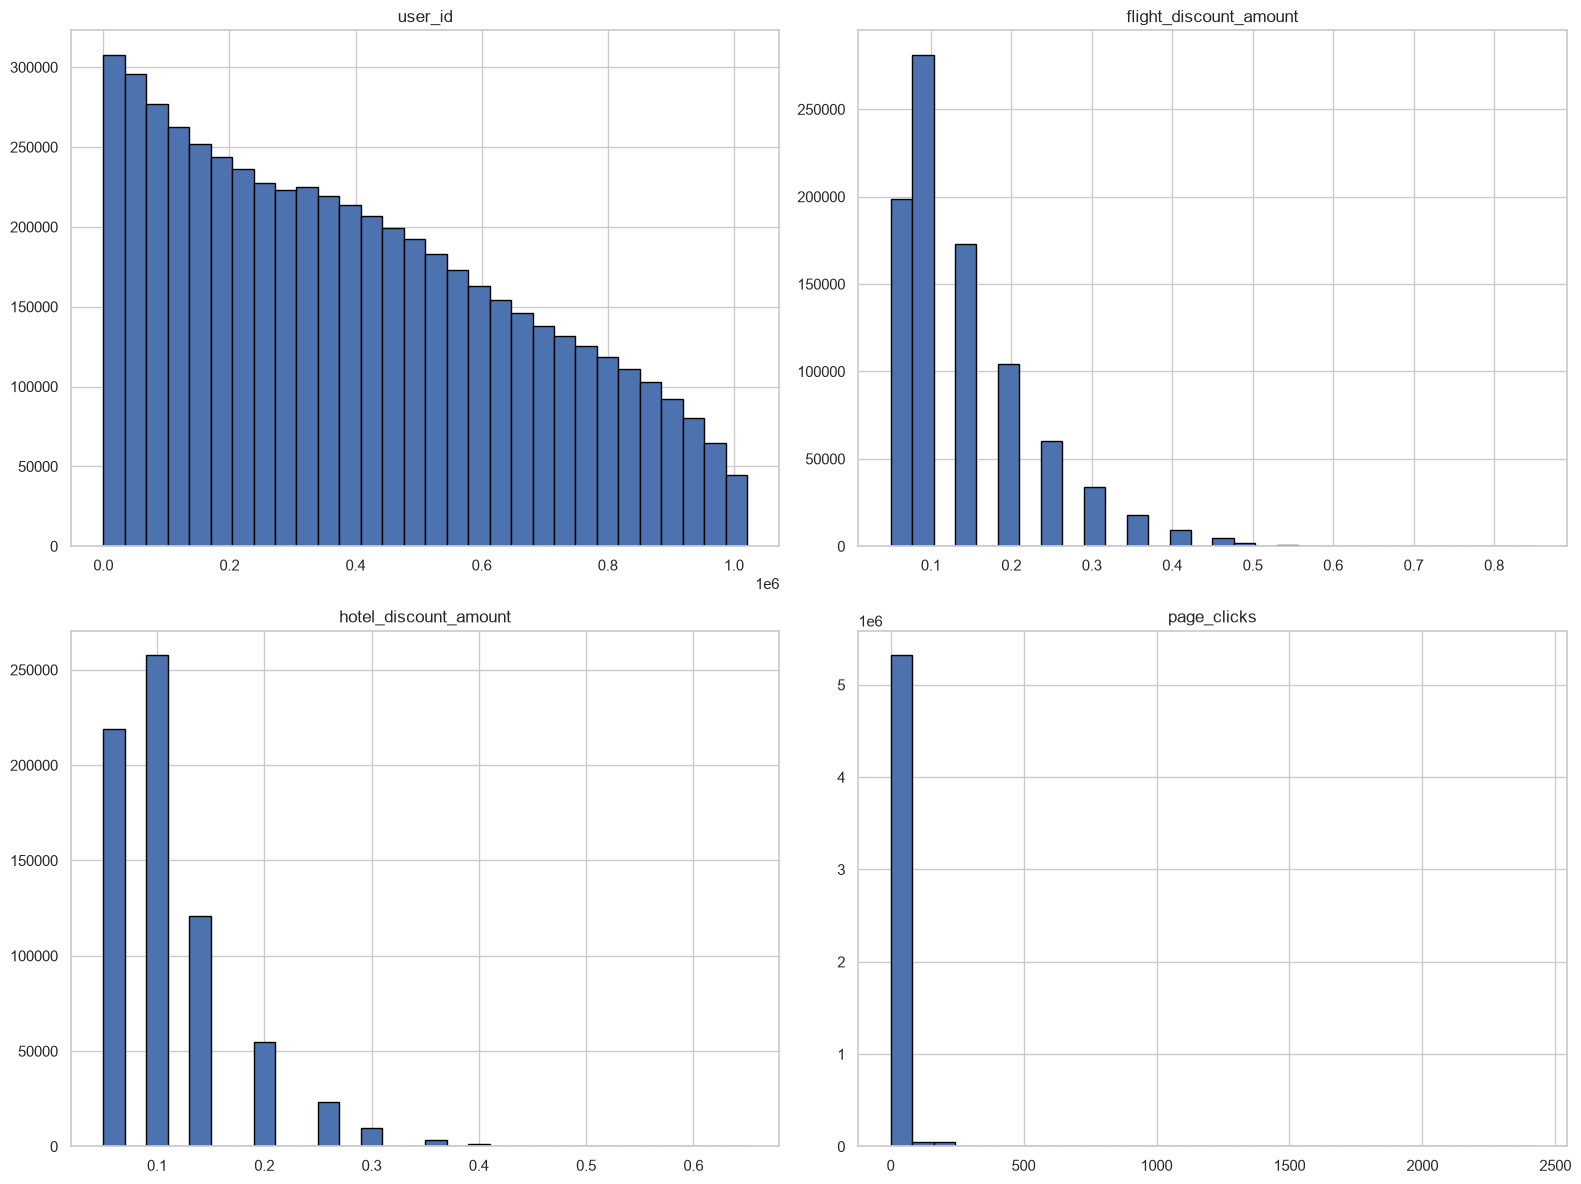

In [20]:
# Verteilung numerischer Variablen
sessions.hist(
    figsize=(16, 12),
    bins=30,
    edgecolor="black"
)

plt.tight_layout()
plt.show()

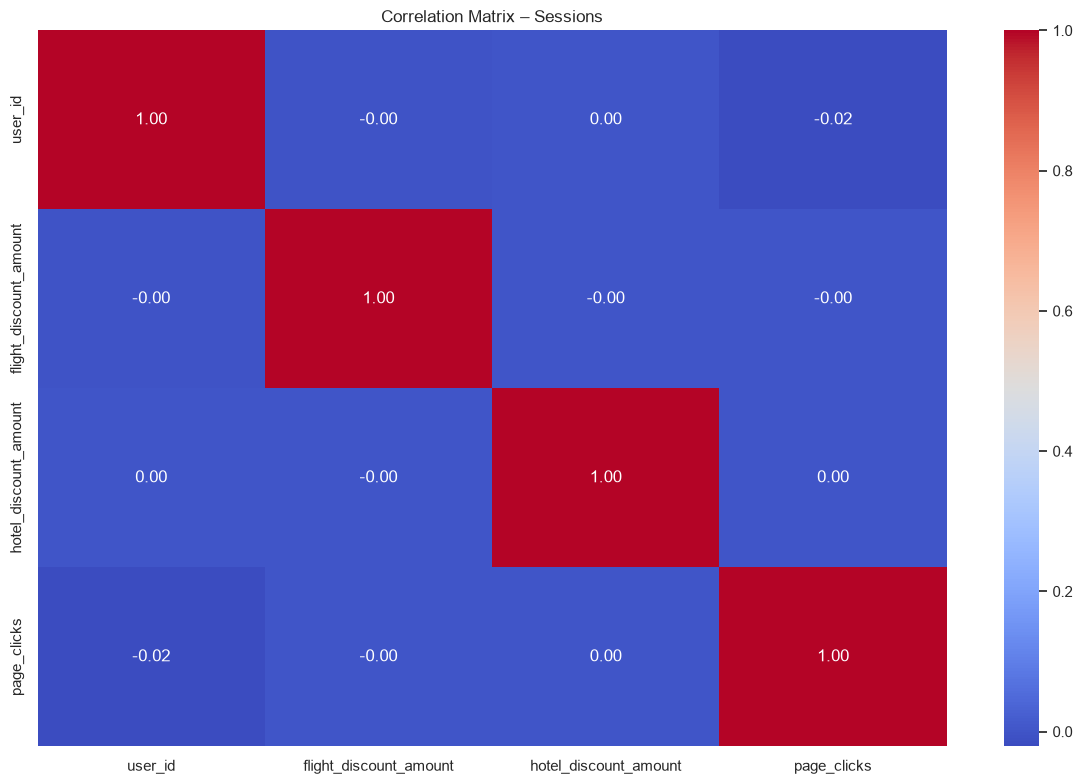

In [21]:
# Nur numerische Spalten berücksichtigen
numeric_sessions = sessions.select_dtypes(include="number")

plt.figure(figsize=(12, 8))

sns.heatmap(
    numeric_sessions.corr(),
    annot=True,
    cmap="coolwarm",
    fmt=".2f"
)

plt.title("Correlation Matrix – Sessions")
plt.tight_layout()
plt.show()

In [22]:
# ============================================================
# TRAVELTIDE – SESSIONS: BOOLEAN CONVERSION
# ============================================================

# 1. Define columns to check and convert
boolean_columns = [
    "flight_discount",
    "hotel_discount",
    "flight_booked",
    "hotel_booked",
    "cancellation"
]

# 2. Check whether all required columns exist
missing_columns = [
    col for col in boolean_columns
    if col not in sessions.columns
]

if missing_columns:
    raise KeyError(
        f"Missing columns in sessions: {missing_columns}"
    )

# 3. Check for NaN values
missing_values = sessions[boolean_columns].isna().sum()

print("Missing values before conversion:")
print(missing_values)

# 4. Convert only if no NaN values are present
if missing_values.sum() == 0:

    for col in boolean_columns:
        values = sessions[col].astype("string").str.strip().str.lower()

        unexpected = values[~values.isin(["f", "t"])]

        if not unexpected.empty:
            raise ValueError(
                f"Unexpected values in column '{col}': "
                f"{unexpected.unique().tolist()}"
            )

        sessions[col] = values.map({
            "f": False,
            "t": True
        })

    print("\nBoolean conversion successful.")

    # 5. Save cleaned dataset

    sessions.to_csv(TARGET_FILE, index=False)

    print(f"\nSaved successfully to:\n{TARGET_FILE}")

else:
    print(
        "\nConversion cancelled: NaN values were found. "
        "Please investigate them first."
    )


Missing values before conversion:
flight_discount    0
hotel_discount     0
flight_booked      0
hotel_booked       0
cancellation       0
dtype: int64

Boolean conversion successful.

Saved successfully to:
D:\MSIT_Schulungsunterlagen\Projekte\TravelTide\data\working\02_inspection\insp_sessions.csv


In [23]:
# Anzahl True und False für alle Binary Columns ermitteln
boolean_counts = pd.DataFrame({
    "True": (sessions[boolean_columns] == True).sum(),
    "False": (sessions[boolean_columns] == False).sum()
})

display(boolean_counts)


,True,False
flight_discount,976466,4431597
hotel_discount,782050,4626013
flight_booked,1991708,3416355
hotel_booked,2009287,3398776
cancellation,90670,5317393
